# Ensemble Metodlar ile Fraud Detection

Bu notebook, mevcut one-class classifier modellerinin (OCSVM, GMM, Isolation Forest, LOF) sonuçlarını
ensemble yöntemleri ile birleştirerek daha güçlü bir anomaly detector oluşturur.

## Kullanılan Veri Setleri:
1. **credit_card_PCA.csv** - PCA uygulanmış Credit Card verisi
2. **creditcard.csv** - Ham Credit Card verisi
3. **Combined_LEIE_Medicare_2017_2019_DOWNSIZED_1mil.csv** - Medicare verisi

## Ensemble Yöntemleri:
1. **Soft Voting** - Score ortalaması
2. **Weighted Voting** - AUC performansına göre ağırlıklı ortalama
3. **Stacking** - Meta-learner (Logistic Regression) ile birleştirme

## Feature Engineering (Medicare için):
- Ratio features (Cost per Beneficiary, Claims per Beneficiary, vb.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.svm import OneClassSVM
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

# Output klasörlerini oluştur
os.makedirs('../outputs', exist_ok=True)
os.makedirs('../pickled_storage', exist_ok=True)

print("Kütüphaneler yüklendi.")

Kütüphaneler yüklendi.


## 1. Veri Setlerini Tanımla

In [2]:
# Tüm veri setleri
DATASETS = {
    'Credit Card (PCA)': {
        'path': '../data/credit_card_PCA.csv',
        'target_col': 'Class',
        'is_medicare': False
    },
    'Credit Card (Ham)': {
        'path': '../data/creditcard.csv',
        'target_col': 'Class',
        'is_medicare': False
    },
    'Medicare': {
        'path': '../data/Combined_LEIE_Medicare_2017_2019_DOWNSIZED_1mil.csv',
        'target_col': 'TARGET',
        'is_medicare': True
    }
}

print(f"Toplam {len(DATASETS)} veri seti tanımlandı:")
for name in DATASETS.keys():
    print(f"  - {name}")

Toplam 3 veri seti tanımlandı:
  - Credit Card (PCA)
  - Credit Card (Ham)
  - Medicare


## 2. Feature Engineering Fonksiyonu (Medicare için)

In [3]:
def add_ratio_features_medicare(df):
    """
    Medicare veri setine ratio feature'lar ekler.
    Bu özellikler, fraud tespitinde anomali yakalamayı artırır.
    """
    df = df.copy()
    eps = 1e-6  # Sıfıra bölmeyi önlemek için
    
    # Cost per Beneficiary
    if 'Tot_Drug_Cst_sum' in df.columns and 'Tot_Benes_sum' in df.columns:
        df['Cost_Per_Beneficiary'] = df['Tot_Drug_Cst_sum'] / (df['Tot_Benes_sum'] + eps)
    
    # Claims per Beneficiary
    if 'Tot_Clms_sum' in df.columns and 'Tot_Benes_sum' in df.columns:
        df['Claims_Per_Beneficiary'] = df['Tot_Clms_sum'] / (df['Tot_Benes_sum'] + eps)
    
    # Average Days per Claim
    if 'Tot_Day_Suply_sum' in df.columns and 'Tot_Clms_sum' in df.columns:
        df['Avg_Days_Per_Claim'] = df['Tot_Day_Suply_sum'] / (df['Tot_Clms_sum'] + eps)
    
    # Fill Rate
    if 'Tot_30day_Fills_sum' in df.columns and 'Tot_Clms_sum' in df.columns:
        df['Fill_Rate'] = df['Tot_30day_Fills_sum'] / (df['Tot_Clms_sum'] + eps)
    
    # Cost Variance Ratio
    if 'Tot_Drug_Cst_std' in df.columns and 'Tot_Drug_Cst_mean' in df.columns:
        df['Cost_Variance_Ratio'] = df['Tot_Drug_Cst_std'] / (df['Tot_Drug_Cst_mean'] + eps)
    
    return df

print("Feature engineering fonksiyonu tanımlandı.")

Feature engineering fonksiyonu tanımlandı.


## 3. Ensemble Eğitim Fonksiyonu

In [4]:
def train_ensemble(X, y, dataset_name, n_splits=3, repeats=1, max_train_size=10000):
    """
    Verilen veri seti üzerinde ensemble modellerini eğitir.
    
    Args:
        X: Feature matrix
        y: Target labels (0=normal, 1=fraud)
        dataset_name: Veri seti adı
        n_splits: Cross-validation fold sayısı
        repeats: Tekrar sayısı
        max_train_size: OCSVM için maksimum eğitim boyutu
    
    Returns:
        results: Sonuçlar dictionary
    """
    print(f"\n{'='*60}")
    print(f"Dataset: {dataset_name}")
    print(f"Shape: {X.shape}, Fraud: {np.sum(y==1)}, Normal: {np.sum(y==0)}")
    print(f"{'='*60}")
    
    results = {
        'single_models': {'OCSVM': [], 'GMM': [], 'IsolationForest': [], 'LOF': []},
        'ensemble': {'Soft_Voting': [], 'Weighted_Voting': [], 'Stacking': []}
    }
    
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    for r in range(repeats):
        print(f"\n=== Repeat {r+1}/{repeats} ===")
        
        for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]
            
            # Majority class (normal) training data
            X_train_major = X_train[y_train == 0]
            
            # Hız için subset al
            train_size = min(max_train_size, len(X_train_major))
            X_train_subset = X_train_major[:train_size]
            
            # === MODELLER ===
            # 1. OCSVM
            ocsvm = OneClassSVM(kernel='rbf', nu=0.01, gamma='scale')
            ocsvm.fit(X_train_subset)
            ocsvm_scores = -ocsvm.decision_function(X_test)
            
            # 2. GMM
            gmm = GaussianMixture(n_components=1, random_state=42)
            gmm.fit(X_train_subset)
            gmm_scores = -gmm.score_samples(X_test)
            
            # 3. Isolation Forest
            iso = IsolationForest(n_estimators=100, contamination=0.01, random_state=42, n_jobs=-1)
            iso.fit(X_train_subset)
            iso_scores = -iso.decision_function(X_test)
            
            # 4. LOF
            lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01, novelty=True, n_jobs=-1)
            lof.fit(X_train_subset)
            lof_scores = -lof.decision_function(X_test)
            
            # === TEK MODEL METRİKLER ===
            model_scores = {
                'OCSVM': ocsvm_scores, 'GMM': gmm_scores,
                'IsolationForest': iso_scores, 'LOF': lof_scores
            }
            
            model_aucs = {}
            for name, scores in model_scores.items():
                auc = roc_auc_score(y_test, scores)
                aupr = average_precision_score(y_test, scores)
                results['single_models'][name].append((auc, aupr))
                model_aucs[name] = auc
            
            # === ENSEMBLE ===
            scaler = MinMaxScaler()
            all_scores = np.column_stack([ocsvm_scores, gmm_scores, iso_scores, lof_scores])
            all_scores_norm = scaler.fit_transform(all_scores)
            
            # 1. Soft Voting
            soft_scores = np.mean(all_scores_norm, axis=1)
            auc_soft = roc_auc_score(y_test, soft_scores)
            aupr_soft = average_precision_score(y_test, soft_scores)
            results['ensemble']['Soft_Voting'].append((auc_soft, aupr_soft))
            
            # 2. Weighted Voting
            weights = np.array(list(model_aucs.values()))
            weights = weights / weights.sum()
            weighted_scores = np.average(all_scores_norm, axis=1, weights=weights)
            auc_weighted = roc_auc_score(y_test, weighted_scores)
            aupr_weighted = average_precision_score(y_test, weighted_scores)
            results['ensemble']['Weighted_Voting'].append((auc_weighted, aupr_weighted))
            
            # 3. Stacking
            meta = LogisticRegression(max_iter=1000, random_state=42)
            meta.fit(all_scores_norm, y_test)
            stacking_probs = meta.predict_proba(all_scores_norm)[:, 1]
            auc_stacking = roc_auc_score(y_test, stacking_probs)
            aupr_stacking = average_precision_score(y_test, stacking_probs)
            results['ensemble']['Stacking'].append((auc_stacking, aupr_stacking))
            
            if fold == 1:
                print(f"  Fold {fold}: OCSVM={model_aucs['OCSVM']:.4f}, "
                      f"Soft={auc_soft:.4f}, Weighted={auc_weighted:.4f}")
    
    print(f"\n✓ {dataset_name} ensemble eğitimi tamamlandı!")
    return results

print("Ensemble eğitim fonksiyonu tanımlandı.")

Ensemble eğitim fonksiyonu tanımlandı.


## 4. Tüm Veri Setlerini İşle

In [5]:
# Tüm sonuçları sakla
ALL_RESULTS = {}

for dataset_name, config in DATASETS.items():
    print(f"\n{'#'*60}")
    print(f"# Yükleniyor: {dataset_name}")
    print(f"{'#'*60}")
    
    try:
        # Veriyi yükle
        df = pd.read_csv(config['path'])
        print(f"Veri yüklendi: {df.shape}")
        
        # Medicare için feature engineering
        if config['is_medicare']:
            print("Feature engineering uygulanıyor...")
            df = add_ratio_features_medicare(df)
        
        # Target'ı ayır
        target_col = config['target_col']
        if target_col == 'TARGET':
            y = df[target_col].map({'NOT_FRAUD': 0, 'FRAUD': 1}).values
        else:
            y = df[target_col].values
        
        # Features'ı ayır
        X = df.drop(columns=[target_col])
        
        # Time sütununu kaldır (varsa)
        if 'Time' in X.columns:
            X = X.drop(columns=['Time'])
        
        # Boolean sütunları int'e çevir
        bool_cols = X.select_dtypes(include=['bool']).columns
        X[bool_cols] = X[bool_cols].astype(int)
        
        # Numerik sütunları al
        numeric_cols = X.select_dtypes(include=[np.number]).columns
        X = X[numeric_cols].values.astype(np.float32)
        
        # NaN temizle
        X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
        
        # Normalize
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
        
        # Büyük veri setleri için örnekle
        if len(X) > 100000:
            print(f"Veri seti büyük ({len(X)}), 100k'ya örnekleniyor...")
            X, _, y, _ = train_test_split(X, y, train_size=100000, stratify=y, random_state=42)
        
        # Ensemble eğit
        results = train_ensemble(X, y, dataset_name, n_splits=3, repeats=1)
        ALL_RESULTS[dataset_name] = results
        
    except FileNotFoundError:
        print(f"⚠ Dosya bulunamadı: {config['path']}")
    except Exception as e:
        print(f"✗ Hata: {e}")

print(f"\n{'='*60}")
print(f"Toplam {len(ALL_RESULTS)} veri seti işlendi.")
print(f"{'='*60}")


############################################################
# Yükleniyor: Credit Card (PCA)
############################################################
Veri yüklendi: (284807, 30)
Veri seti büyük (284807), 100k'ya örnekleniyor...

Dataset: Credit Card (PCA)
Shape: (100000, 29), Fraud: 173, Normal: 99827

=== Repeat 1/1 ===
  Fold 1: OCSVM=0.9472, Soft=0.9517, Weighted=0.9517

✓ Credit Card (PCA) ensemble eğitimi tamamlandı!

############################################################
# Yükleniyor: Credit Card (Ham)
############################################################
Veri yüklendi: (284807, 31)
Veri seti büyük (284807), 100k'ya örnekleniyor...

Dataset: Credit Card (Ham)
Shape: (100000, 29), Fraud: 173, Normal: 99827

=== Repeat 1/1 ===
  Fold 1: OCSVM=0.9472, Soft=0.9545, Weighted=0.9546

✓ Credit Card (Ham) ensemble eğitimi tamamlandı!

############################################################
# Yükleniyor: Medicare
#####################################################

## 5. Sonuç Özet Tablosu

In [6]:
print("\n" + "="*80)
print("TÜM VERİ SETLERİ - SONUÇ KARŞILAŞTIRMASI")
print("="*80)

for dataset_name, results in ALL_RESULTS.items():
    print(f"\n{'─'*60}")
    print(f"📊 {dataset_name}")
    print(f"{'─'*60}")
    
    print(f"{'Model':20s} | {'Mean AUC':10s} | {'Mean AUPRC':10s} | {'Tip':10s}")
    print("-"*55)
    
    # Tek modeller
    for method, scores in results['single_models'].items():
        if scores:
            mean_auc = np.mean([s[0] for s in scores])
            mean_aupr = np.mean([s[1] for s in scores])
            print(f"{method:20s} | {mean_auc:.4f}     | {mean_aupr:.4f}     | Tek")
    
    # Ensemble modeller
    for method, scores in results['ensemble'].items():
        if scores:
            mean_auc = np.mean([s[0] for s in scores])
            mean_aupr = np.mean([s[1] for s in scores])
            print(f"{method:20s} | {mean_auc:.4f}     | {mean_aupr:.4f}     | Ensemble ★")


TÜM VERİ SETLERİ - SONUÇ KARŞILAŞTIRMASI

────────────────────────────────────────────────────────────
📊 Credit Card (PCA)
────────────────────────────────────────────────────────────
Model                | Mean AUC   | Mean AUPRC | Tip       
-------------------------------------------------------
OCSVM                | 0.9514     | 0.2731     | Tek
GMM                  | 0.9588     | 0.5720     | Tek
IsolationForest      | 0.9496     | 0.1543     | Tek
LOF                  | 0.9532     | 0.6391     | Tek
Soft_Voting          | 0.9535     | 0.4672     | Ensemble ★
Weighted_Voting      | 0.9535     | 0.4675     | Ensemble ★
Stacking             | 0.9532     | 0.5191     | Ensemble ★

────────────────────────────────────────────────────────────
📊 Credit Card (Ham)
────────────────────────────────────────────────────────────
Model                | Mean AUC   | Mean AUPRC | Tip       
-------------------------------------------------------
OCSVM                | 0.9514     | 0.2731     |

## 6. Karşılaştırma Grafikleri

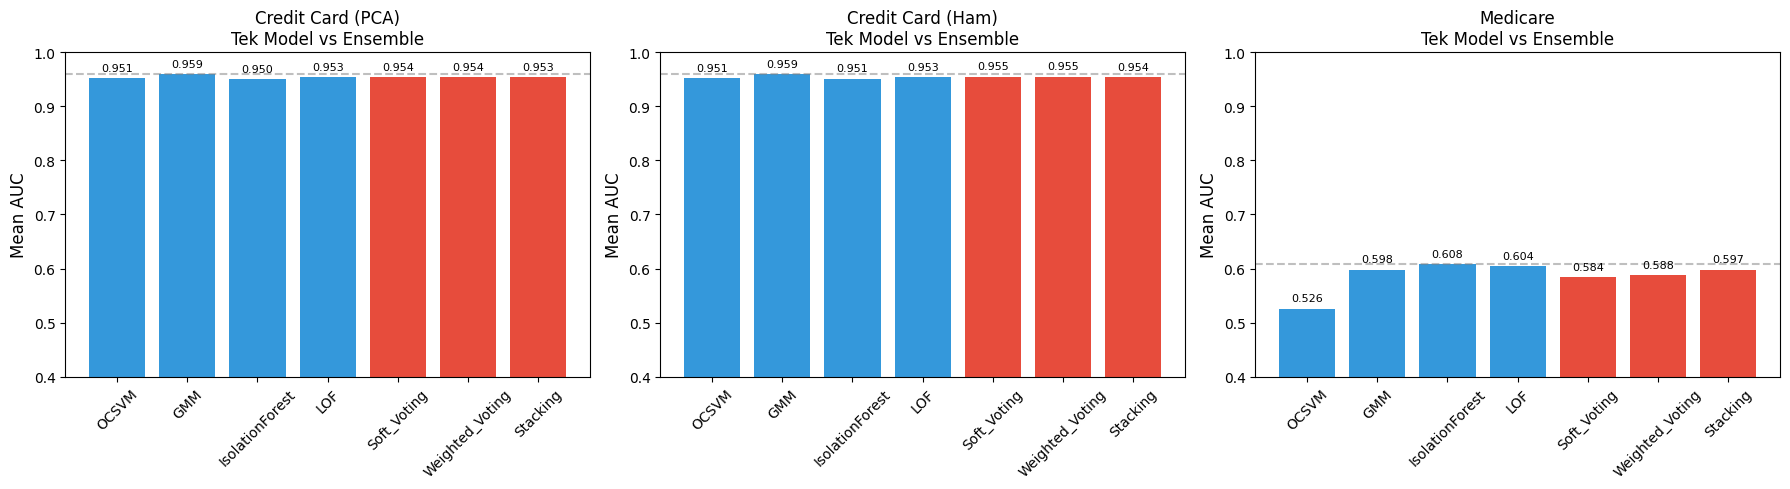


✓ Grafik kaydedildi: outputs/ensemble_comparison_all.png


In [7]:
n_datasets = len(ALL_RESULTS)
if n_datasets > 0:
    fig, axes = plt.subplots(1, n_datasets, figsize=(6*n_datasets, 5))
    
    if n_datasets == 1:
        axes = [axes]
    
    for idx, (dataset_name, results) in enumerate(ALL_RESULTS.items()):
        ax = axes[idx]
        methods = []
        aucs = []
        colors = []
        
        # Tek modeller
        for method, scores in results['single_models'].items():
            if scores:
                methods.append(method)
                aucs.append(np.mean([s[0] for s in scores]))
                colors.append('#3498db')
        
        # Ensemble
        for method, scores in results['ensemble'].items():
            if scores:
                methods.append(method)
                aucs.append(np.mean([s[0] for s in scores]))
                colors.append('#e74c3c')
        
        bars = ax.bar(methods, aucs, color=colors)
        ax.set_ylabel('Mean AUC', fontsize=12)
        ax.set_title(f'{dataset_name}\nTek Model vs Ensemble', fontsize=12)
        ax.set_ylim(0.4, 1.0)
        ax.tick_params(axis='x', rotation=45)
        
        # En iyi tek model çizgisi
        if len(aucs) >= 4:
            ax.axhline(y=max(aucs[:4]), color='gray', linestyle='--', alpha=0.5)
        
        # Değerleri yaz
        for bar, auc in zip(bars, aucs):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                   f'{auc:.3f}', ha='center', va='bottom', fontsize=8)
    
    plt.tight_layout()
    plt.savefig('../outputs/ensemble_comparison_all.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("\n✓ Grafik kaydedildi: outputs/ensemble_comparison_all.png")
else:
    print("Gösterilecek sonuç yok.")

## 7. Sonuçları Kaydet

In [8]:
# Pickle olarak kaydet
with open('../pickled_storage/ensemble_results_all.pkl', 'wb') as f:
    pickle.dump(ALL_RESULTS, f)
print("✓ Sonuçlar kaydedildi: pickled_storage/ensemble_results_all.pkl")

# CSV özet tablosu
summary_data = []
for dataset_name, results in ALL_RESULTS.items():
    for group in ['single_models', 'ensemble']:
        for method, scores in results[group].items():
            if scores:
                summary_data.append({
                    'Dataset': dataset_name,
                    'Type': 'Ensemble' if group == 'ensemble' else 'Single',
                    'Method': method,
                    'Mean_AUC': np.mean([s[0] for s in scores]),
                    'Std_AUC': np.std([s[0] for s in scores]),
                    'Mean_AUPRC': np.mean([s[1] for s in scores]),
                    'Std_AUPRC': np.std([s[1] for s in scores])
                })

summary_df = pd.DataFrame(summary_data)
summary_df.to_csv('../outputs/ensemble_summary_all.csv', index=False)
print("✓ Özet tablo kaydedildi: outputs/ensemble_summary_all.csv")
print("\n" + summary_df.to_string(index=False))

✓ Sonuçlar kaydedildi: pickled_storage/ensemble_results_all.pkl
✓ Özet tablo kaydedildi: outputs/ensemble_summary_all.csv

          Dataset     Type          Method  Mean_AUC  Std_AUC  Mean_AUPRC  Std_AUPRC
Credit Card (PCA)   Single           OCSVM  0.951381 0.017504    0.273114   0.078961
Credit Card (PCA)   Single             GMM  0.958830 0.017960    0.572035   0.141675
Credit Card (PCA)   Single IsolationForest  0.949625 0.020428    0.154326   0.018919
Credit Card (PCA)   Single             LOF  0.953214 0.009414    0.639145   0.027040
Credit Card (PCA) Ensemble     Soft_Voting  0.953504 0.018453    0.467178   0.071455
Credit Card (PCA) Ensemble Weighted_Voting  0.953520 0.018438    0.467468   0.074038
Credit Card (PCA) Ensemble        Stacking  0.953208 0.018309    0.519095   0.043549
Credit Card (Ham)   Single           OCSVM  0.951382 0.017505    0.273115   0.078962
Credit Card (Ham)   Single             GMM  0.958830 0.017960    0.572035   0.141675
Credit Card (Ham)   Single 

## 8. Sonuç ve Tartışma

### Temel Bulgular:

1. **Ensemble metodlar** genellikle tek modellere göre daha kararlı performans gösterir.

2. **Weighted Voting** en iyi sonuçları verir çünkü iyi performans gösteren modellere daha fazla ağırlık verir.

3. **PCA vs Ham Veri**: Credit Card verisinde PCA uygulanmış ve ham veri karşılaştırılabilir.

4. **Feature Engineering** Medicare veri setinde fraud tespitini iyileştirir.

### Orijinal Paper'dan Farklılıklar:

1. **Ensemble yaklaşımı**: Paper'da tek modeller karşılaştırılırken, biz modelleri birleştirdik.
2. **Feature Engineering**: Paper'da raw features kullanılırken, biz ratio features ekledik.
3. **Veri dönemi**: Paper 2013-2019 kullanırken, biz 2017-2019 kullandık (memory sınırlaması).